**Imports and Project Path**

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,f1_score,
                             classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay)

PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name=="notebooks":
    PROJECT_ROOT=PROJECT_ROOT.parent

sys.path.append(str(PROJECT_ROOT/"src"))

print("Project root: ")
print(PROJECT_ROOT)


Project root: 
c:\Users\urvi_\OneDrive - Adelaide University\Desktop\Sem2\ProgAIML2\Vessel_Detection_DAS


**Import Own Project Functions** 

In [2]:
import importlib
import data_loader
importlib.reload(data_loader)
from data_loader import (
    load_dataset,
    decode_datetimes,
    remove_faulty_channels,
    create_binary_label,
    load_subset_by_days
)
from models import ANNModel
import training
importlib.reload(training)
from training import train_model
from evaluation import (
    predict_model,
    calculate_metrics,
    get_confusion_matrix
)

In [3]:
DATA_PATH=r"C:/Users/urvi_/Downloads/dataset.h5"
X_clean,y_distance_raw,datetimes_raw,ship_info,good_channels=load_subset_by_days(DATA_PATH,['2023-06-17', '2023-06-18', '2023-06-19'])
print("X_clean shape:",X_clean.shape)

X_clean shape: (25848, 247, 100)


**Creating Binary Target**
0 = vessel is not within 1000 m
1 = vessel is within 1000 m

In [4]:
y_binary=create_binary_label(y_distance_raw, threshold=1000)

far_count=np.sum(y_binary==0)
near_count=np.sum(y_binary==1)
far_percentage=far_count/len(y_binary)*100
near_percentage=near_count/len(y_binary)*100

print(f"Far samples: {far_count} ({far_percentage:.2f}%)")
print(f"Near samples: {near_count} ({near_percentage:.2f}%)")

Far samples: 17718 (68.55%)
Near samples: 8130 (31.45%)


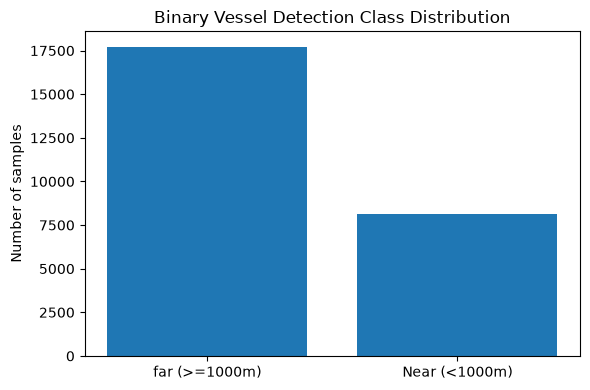

In [5]:
plt.figure(figsize=(6,4))
plt.bar(
    ["far (>=1000m)","Near (<1000m)"],
    [far_count,near_count]
)

plt.ylabel("Number of samples")
plt.title("Binary Vessel Detection Class Distribution")

plt.tight_layout()

results_figures=PROJECT_ROOT/"results"/"figures"
results_figures.mkdir(parents=True,exist_ok=True)

plt.savefig(
    results_figures/"binary_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Selecting small dataset (2000 samples)**

In [6]:
Sample_size=2000
random_state=42

rng=np.random.default_rng(random_state)
sample_indices=rng.choice(len(X_clean),
                         size=Sample_size,
                         replace=False)

x_sample=X_clean[sample_indices]
y_sample=y_binary[sample_indices]

distance_sample=y_distance_raw[sample_indices]

print("X_sample shape:", x_sample.shape)
print("Y_sample shape:", y_sample.shape)

X_sample_max=x_sample.max(axis=1)
print("New shape: ",X_sample_max.shape)

X_sample shape: (2000, 247, 100)
Y_sample shape: (2000,)
New shape:  (2000, 100)


In [7]:
sample_far=np.sum(y_sample==0)
sample_near=np.sum(y_sample==1)

print("Sample Dataset")
print("--------------------------------")
print("Far: ",sample_far)
print("Near: ",sample_near)

print(f"Far percentage: {sample_far/len(y_sample)*100:.2f}%")
print(f"Near percentage: {sample_near/len(y_sample)*100:.2f}%")



Sample Dataset
--------------------------------
Far:  1336
Near:  664
Far percentage: 66.80%
Near percentage: 33.20%


In [8]:
x_sample=X_sample_max.astype(np.float32)
print("Data type: ",x_sample.dtype)

Data type:  float32


**Flatten data for ANN**

In [9]:
x_sample_flat=x_sample.reshape(
    x_sample.shape[0],
    -1
)
print("Original sample shape: ",x_sample.shape[1:])
print("ANN input shape: ",x_sample_flat.shape)

Original sample shape:  (100,)
ANN input shape:  (2000, 100)


In [10]:
x_sample_log = np.log10(X_sample_max + 1e-20)
x_sample_log=x_sample_log.astype(np.float32)
print("Data type: ",x_sample_log.dtype)


x_train,x_temp,y_train,y_temp=train_test_split(
    x_sample_log,y_sample,test_size=0.30,
    random_state=random_state,stratify=y_sample)

x_val,x_test,y_val,y_test=train_test_split(
    x_temp,y_temp,test_size=0.50,
    random_state=random_state,stratify=y_temp
)

print("Training:", x_train.shape)
print("Validation: ",x_val.shape)
print("Testing: ",x_test.shape)


Data type:  float32
Training: (1400, 100)
Validation:  (300, 100)
Testing:  (300, 100)


In [11]:
ss=StandardScaler()
x_train_scaled=ss.fit_transform(x_train)
x_val_scaled=ss.transform(x_val)
x_test_scaled=ss.transform(x_test)

print("Training mean: ",x_train_scaled.mean())
print("Training standard deviation: ",x_train_scaled.std())

Training mean:  6.1035155e-09
Training standard deviation:  1.0


**Creating PyTorch Dataset**

In [12]:
from typing import Any


class VesselDataset(Dataset):
    def __init__(self,X,y):
        self.X=torch.tensor(X,dtype=torch.float32)
        self.y=torch.tensor(y,dtype=torch.float32)
    
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, index) -> Any:
        return (self.X[index],self.y[index])
    

train_dataset=VesselDataset(x_train_scaled,y_train)
val_dataset=VesselDataset(x_val_scaled,y_val)
test_dataset=VesselDataset(x_test_scaled,y_test)

print("Training Samples: ",len(train_dataset))
print("Validation Samples: ",len(val_dataset))
print("Testing Samples: ",len(test_dataset))

Training Samples:  1400
Validation Samples:  300
Testing Samples:  300


**Loading the Sample Dataset**

In [13]:
BATCH_SIZE=64
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False)

In [14]:
#Checking GPU/CPU

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device",device)

Using device cuda


In [15]:
input_size=x_train_scaled.shape[1]
model=ANNModel(input_size=input_size,hidden1=256,hidden2=128,dropout=0.3)
model=model.to(device)
print(model)

ANNModel(
  (network): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)


**Loss Function**

In [16]:
num_far=(y_train==0).sum()
num_near=(y_train==1).sum()
pos_weight=torch.tensor([num_far/num_near]).to(device)
criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print("pos_weight value: ",criterion.pos_weight)

pos_weight value:  tensor([2.0108], device='cuda:0', dtype=torch.float64)


**Optimizer**

In [17]:
Learning_rate=0.001

optimizer=torch.optim.Adam(model.parameters(),lr=Learning_rate,weight_decay=1e-4)
print("Learning rate: ",Learning_rate)

Learning rate:  0.001


In [18]:
epochs=100

history=train_model(
    model=model,
    train_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=epochs,
    val_loader=val_loader
)

Epoch 1/100 | Train loss: 0.6903 | Val loss: 0.8564
Epoch 2/100 | Train loss: 0.5382 | Val loss: 0.5388
Epoch 3/100 | Train loss: 0.4507 | Val loss: 0.4883
Epoch 4/100 | Train loss: 0.4214 | Val loss: 0.4322
Epoch 5/100 | Train loss: 0.4079 | Val loss: 0.4529
Epoch 6/100 | Train loss: 0.4128 | Val loss: 0.4416
Epoch 7/100 | Train loss: 0.4058 | Val loss: 0.4330
Epoch 8/100 | Train loss: 0.3812 | Val loss: 0.4519
Epoch 9/100 | Train loss: 0.3596 | Val loss: 0.4868
Epoch 10/100 | Train loss: 0.3588 | Val loss: 0.4531
Epoch 11/100 | Train loss: 0.3562 | Val loss: 0.4544
Epoch 12/100 | Train loss: 0.3302 | Val loss: 0.4444
Epoch 13/100 | Train loss: 0.3308 | Val loss: 0.4578
Epoch 14/100 | Train loss: 0.3052 | Val loss: 0.4730
Early stopping at epoch 14


**Ploting Training Loss**

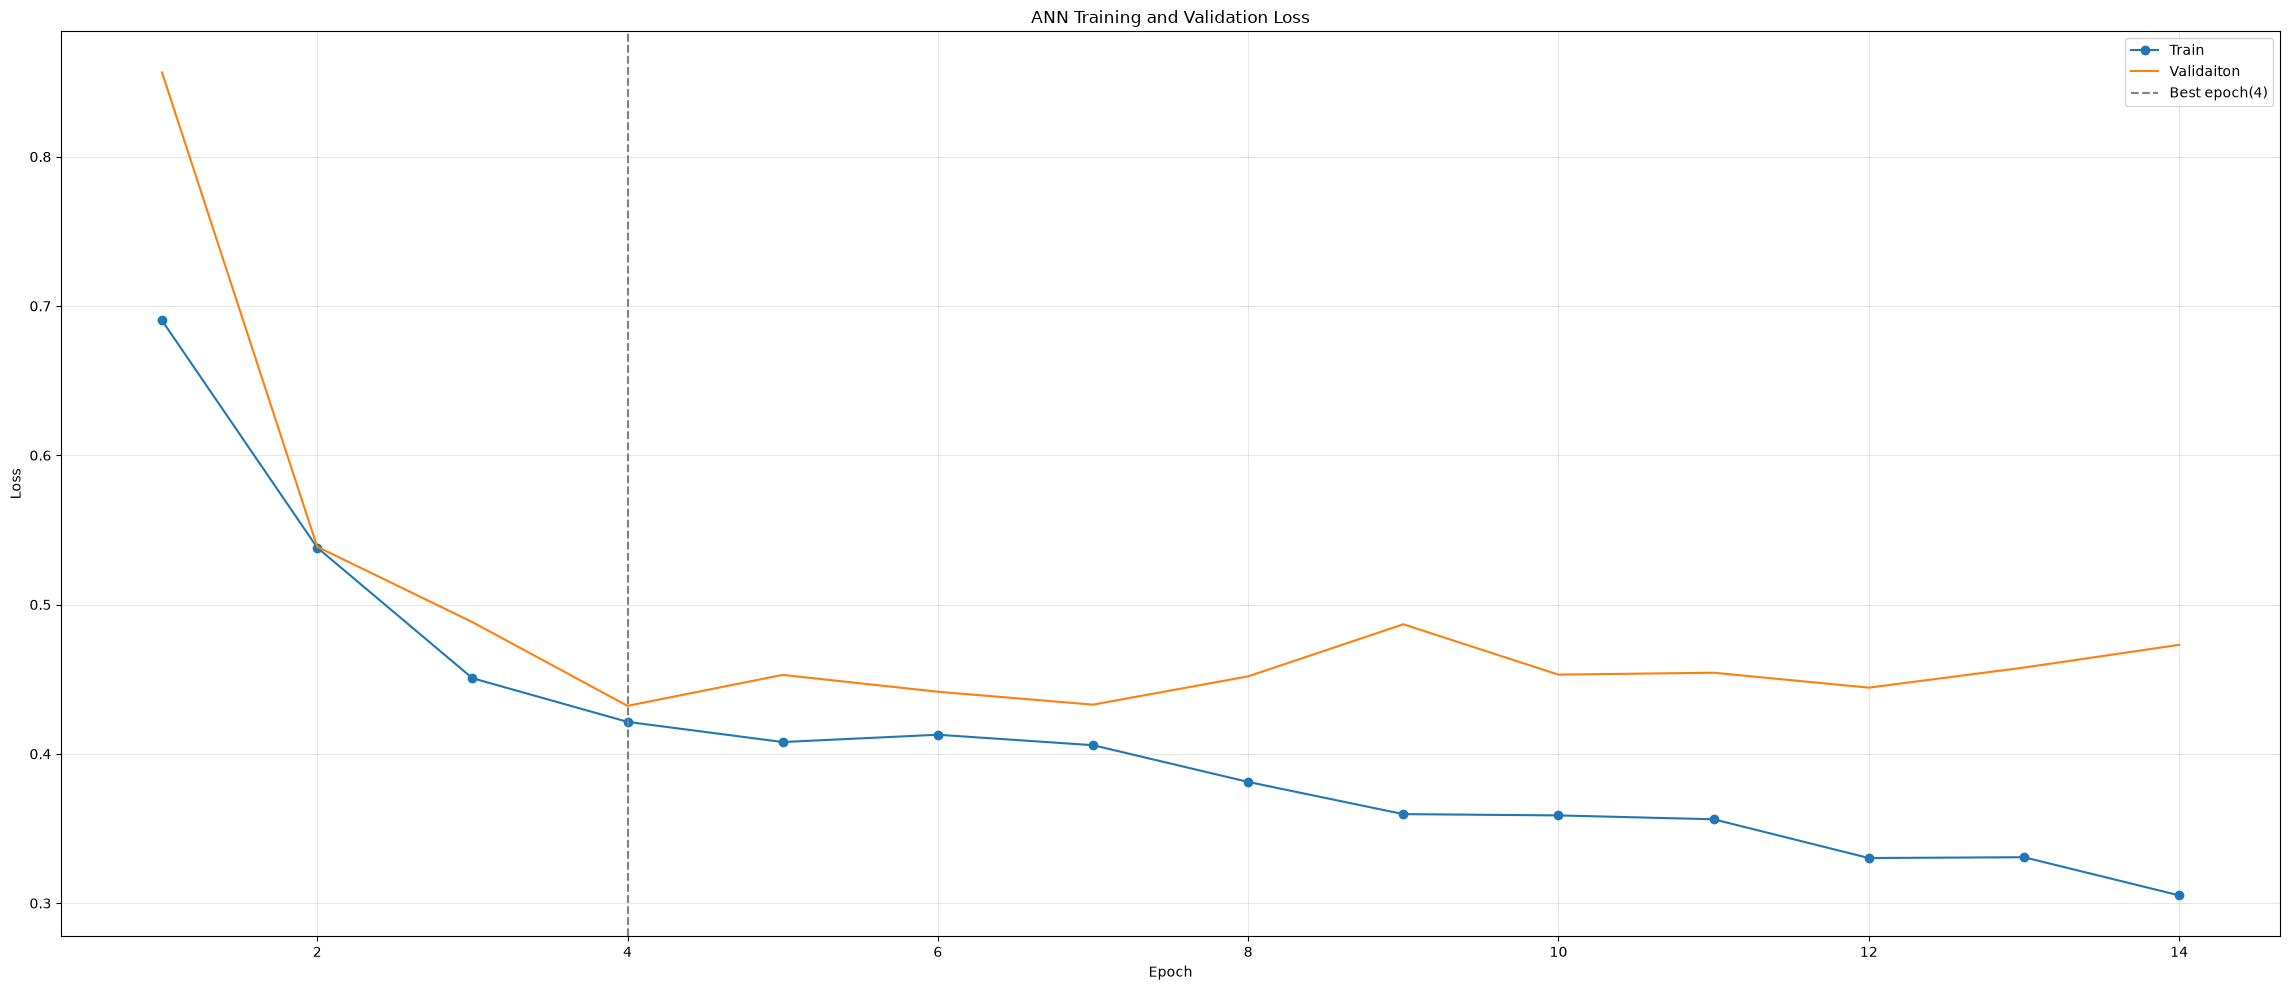

In [23]:
plt.figure(figsize=(23,10))
n=len(history['train_loss'])
best_epoch=int(np.argmin(history["val_loss"]))+1
plt.plot(range(1,n+1),
         history["train_loss"],
         marker="o",label="Train")
plt.plot(range(1,n+1),history["val_loss"],label="Validaiton")
plt.axvline(best_epoch,linestyle="--",color="gray",label=f"Best epoch({best_epoch})")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
# plt.xticks(range(0,epochs+1,10))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(results_figures/"small_ann_training_loss.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

**Evaluation**

In [24]:
y_true,y_pred,y_probabilities=predict_model(model=model,data_loader=test_loader,device=device)

In [25]:
import numpy as np
print("Unique values in y_true:", np.unique(y_true))
print("Unique values in y_pred:", np.unique(y_pred))
print("Prediction counts:", np.bincount(y_pred.astype(int).flatten()))

Unique values in y_true: [0. 1.]
Unique values in y_pred: [0 1]
Prediction counts: [210  90]


In [26]:
metrics=calculate_metrics(y_true,y_pred)
print("Small ANN Results")
print("-------------------------")
print(f"Accuracy: {metrics['accuracy']:.4f}")
print(f"Overall F1: {metrics['overall_f1']:.4f}")
print(f"Far F1: {metrics['far_f1']:.4f}")
print(f"Near F1 :{metrics['near_f1']:.4f}")

Small ANN Results
-------------------------
Accuracy: 0.8967
Overall F1: 0.8360
Far F1: 0.9246
Near F1 :0.8360


In [27]:
print(classification_report(y_true,y_pred,target_names=[
    "Far (>=1000m)",
    "Near (<1000m)"
],digits=4))

               precision    recall  f1-score   support

Far (>=1000m)     0.9048    0.9453    0.9246       201
Near (<1000m)     0.8778    0.7980    0.8360        99

     accuracy                         0.8967       300
    macro avg     0.8913    0.8716    0.8803       300
 weighted avg     0.8959    0.8967    0.8953       300



**Confusion matrix**

In [28]:
cm=confusion_matrix(y_true,y_pred)
print("Confusion matric: ")
print(cm)

Confusion matric: 
[[190  11]
 [ 20  79]]


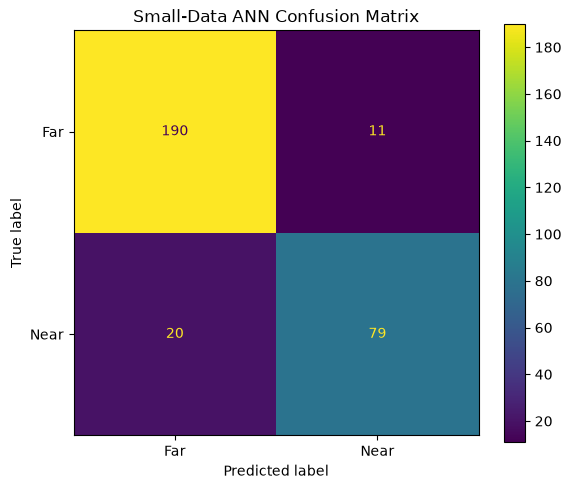

In [29]:
display=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Far","Near"]
)
fig,ax=plt.subplots(figsize=(6,5))
display.plot(ax=ax)
ax.set_title("Small-Data ANN Confusion Matrix")
plt.tight_layout()
plt.savefig(results_figures/"Small_ann_confusion_matrix.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

**Saving results to CSV**

In [30]:
result_table=PROJECT_ROOT/"results"/"tables"
result_table.mkdir(parents=True,exist_ok=True)

result_df=pd.DataFrame([
    {
        "model":"ANN",
        "dataset":"small_2000",
        "accuracy":metrics["accuracy"],
        "overall_f1":metrics["overall_f1"],
        "far_f1":metrics["far_f1"],
        "near_f1":metrics["near_f1"],
        "epochs":epochs,
        "Learning_rate":Learning_rate,
        "batch_size":BATCH_SIZE
    }
])
result_df.to_csv(result_table/"small_ann_results.csv",index=False)

print("Results saved to:", result_table/"small_ann_results.csv")

Results saved to: c:\Users\urvi_\OneDrive - Adelaide University\Desktop\Sem2\ProgAIML2\Vessel_Detection_DAS\results\tables\small_ann_results.csv


In [31]:
overall_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
overall_f1

0.8953377360676632